# Prim Algorithm

## Edges List

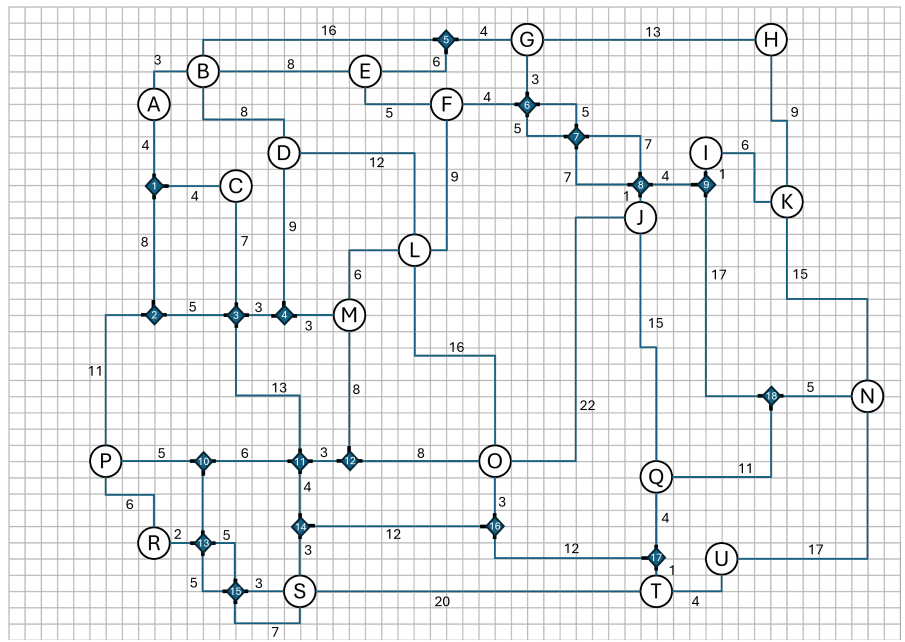

In [13]:
edges = [
    ("B", "5", 16), ("5", "G", 4), ("G", "H", 13),
    ("B", "D", 8), ("A", "B", 3), ("A", "1", 4),
    ("B", "E", 8), ("E", "F", 5), ("E", "5", 6),
    ("F", "6", 4), ("F", "L", 9), ("G", "6", 3),
    ("6", "7", 5), ("6", "7", 5), ("7", "8", 7),
    ("7", "8", 7), ("8", "J", 1), ("8", "9", 4),
    ("J", "Q", 15), ("9", "I", 1), ("9", "18", 17),
    ("I", "K", 6), ("H", "K", 9), ("K", "N", 15),
    ("18", "N", 5), ("18", "Q", 11), ("J", "O", 22),
    ("Q", "17", 4), ("17", "T", 1), ("T", "U", 4),
    ("U", "N", 17), ("1", "C", 4), ("1", "2", 8),
    ("C", "3", 7), ("2", "3", 5), ("2", "P", 11),
    ("3", "4", 3), ("4", "D", 9), ("4", "M", 3),
    ("3", "11", 13), ("D", "L", 12), ("L", "M", 6),
    ("L", "O", 16), ("M", "12", 8), ("11", "12", 3),
    ("11", "14", 4), ("12", "O", 8), ("O", "16", 3),
    ("14", "16", 12), ("14", "S", 3), ("16", "17", 12),
    ("P", "10", 5), ("P", "R", 6), ("10", "11", 6),
    ("10", "13", 5), ("R", "13", 2), ("13", "15", 5),
    ("15", "S", 3), ("15", "S", 7), ("S", "T", 20),
]

## Adjacent List

In [14]:
def create_adjacentlist (edges):
    adj = {}

    for u, v, w in edges:
        if u not in adj:
            adj[u] = {}
        if v not in adj:
            adj[v] = {}

        if v not in adj[u]:
            adj[u][v] = w
            adj[v][u] = w
        else:
            adj[u][v] = min (adj[u][v], w)
            adj[v][u] = min (adj[v][u], w)

    return adj
# Output: adj = {"A": {"B": 3, "C": 2}, "B": {"A": 3, "C": 1}, ...}

## Adjacent Matrix

In [15]:
def create_adjacentmatrix (edges):
    nodes = set()
    for u, v, _ in edges:
        nodes.add(u)
        nodes.add(v)
    nodes = list(nodes)

    idx = {node: i for i, node in enumerate(nodes)}

    adj = [[float('inf') for _ in range(len(nodes))] for _ in range(len(nodes))]

    for node in nodes:
        adj[idx[node]][idx[node]] = 0

    for u, v, w in edges:
        if w < adj[idx[u]][idx[v]]:
            adj[idx[u]][idx[v]] = w
            adj[idx[v]][idx[u]] = w

    return nodes, idx, adj

## Prim Algorithm

In [16]:
def prim (edges, start):
    nodes, idx, _ = create_adjacentmatrix(edges)
    adj_list = create_adjacentlist(edges)
    n = len(nodes)

    visited = [False] * n
    visited[idx[start]] = True

    path = []
    total_cost = 0

    while True:
        min_weight = float('inf')
        start_node = None
        end_node = None

        for u in nodes:
            if visited[idx[u]]:
                for v, w in adj_list.get(u, {}).items():
                    if not visited[idx[v]]:
                        if w < min_weight:
                            min_weight = w
                            start_node = u
                            end_node = v

        if min_weight < float('inf'):
            visited[idx[end_node]] = True
            path.append((start_node, end_node, min_weight))
            total_cost += min_weight

            if len(path) == n-1:
                break
        else:
            break

    return path, total_cost

## Test Run

In [17]:
# --- Test Run ---
if __name__ == "__main__":
    start_node = "A"
    mst_edges, total_cost = prim(edges, start=start_node)

    print("=" * 55)
    print("        PRIM'S ALGORITHM (MST) - RESULT")
    print("=" * 55)
    print(f"Starting Node : {start_node}")
    print(f"Edges in MST  : {len(mst_edges)} edges")
    print(f"Total Weight  : {total_cost}")
    print("=" * 55)
    print("\nFirst 10 edges selected by Prim:")
    for u, v, w in mst_edges[:10]:
        print(f"  Edge ({u} - {v}) with weight {w}")

        PRIM'S ALGORITHM (MST) - RESULT
Starting Node : A
Edges in MST  : 38 edges
Total Weight  : 186

First 10 edges selected by Prim:
  Edge (A - B) with weight 3
  Edge (A - 1) with weight 4
  Edge (1 - C) with weight 4
  Edge (C - 3) with weight 7
  Edge (3 - 4) with weight 3
  Edge (4 - M) with weight 3
  Edge (3 - 2) with weight 5
  Edge (M - L) with weight 6
  Edge (B - D) with weight 8
  Edge (B - E) with weight 8
